# 📦 Notebook 1: Data Preparation & Preprocessing

## Objective
This notebook is the **foundation** of the entire binary classification pipeline.
It handles:
1. Loading and understanding the ISIC 2019 metadata
2. Mapping 8 lesion classes → 2 binary classes (Benign vs Malignant)
3. Applying **DullRazor** (Hair Removal) preprocessing
4. Applying **Shades of Gray** (Color Constancy) normalization
5. Performing a **Stratified 80/10/10 Split** (no data leakage)
6. Exporting clean CSVs for downstream training notebooks

## Class Mapping Strategy
| Original Class | Label | Binary Target |
|---|---|---|
| NV (Melanocytic Nevus) | nv | 0 - Benign |
| BKL (Benign Keratosis) | bkl | 0 - Benign |
| DF (Dermatofibroma) | df | 0 - Benign |
| VASC (Vascular Lesion) | vasc | 0 - Benign |
| MEL (Melanoma) | mel | 1 - Malignant |
| BCC (Basal Cell Carcinoma) | bcc | 1 - Malignant |
| SCC (Squamous Cell Carcinoma) | scc | 1 - Malignant |
| AK (Actinic Keratosis) | ak| 1 - Malignant |

> **Note:** AK is a pre-cancerous lesion clinically treated and flagged as malignant.
"""

In [1]:
# ── CODE CELL 1: Install & Import Libraries ───────────────────────────
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries imported successfully.")
print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ Libraries imported successfully.
OpenCV version: 4.13.0
NumPy version: 2.0.2
Pandas version: 2.3.3



## Step 1: Load the ISIC 2019 Metadata
The ground truth CSV contains one-hot encoded columns for each of the 8 classes.
We will inspect the data before doing any transformation.


In [2]:
# ── CODE CELL 2: Load & Inspect Metadata ─────────────────────────────
# ── IMPORTANT: Update these paths to match your Kaggle dataset location ──
CSV_PATH   = '/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_GroundTruth.csv'
IMAGE_DIR  = '/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Input/ISIC_2019_Training_Input'
OUTPUT_DIR = '/kaggle/working/'
PREP_DIR   = '/kaggle/working/preprocessed/'

os.makedirs(PREP_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

print("=" * 55)
print("  ISIC 2019 Dataset Overview")
print("=" * 55)
print(f"  Total Images      : {len(df):,}")
print(f"  Columns           : {list(df.columns)}")
print("\n  Class Distribution (Raw 8-class):")
print("=" * 55)

class_cols = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
for cls in class_cols:
    count = int(df[cls].sum())
    pct   = count / len(df) * 100
    print(f"  {cls:<8}: {count:>6,} images  ({pct:>5.1f}%)")

print("=" * 55)
df.head()

  ISIC 2019 Dataset Overview
  Total Images      : 25,331
  Columns           : ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']

  Class Distribution (Raw 8-class):
  MEL     :  4,522 images  ( 17.9%)
  NV      : 12,875 images  ( 50.8%)
  BCC     :  3,323 images  ( 13.1%)
  AK      :    867 images  (  3.4%)
  BKL     :  2,624 images  ( 10.4%)
  DF      :    239 images  (  0.9%)
  VASC    :    253 images  (  1.0%)
  SCC     :    628 images  (  2.5%)


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 2: Binary Label Engineering
Map all 8 classes into 2 clinical buckets:
- **Class 0 (Benign):** NV, BKL, DF, VASC
- **Class 1 (Malignant):** MEL, BCC, SCC, AK

In [3]:
# ── CODE CELL 3: Apply Binary Mapping ────────────────────────────────
MALIGNANT_CLASSES = ['MEL', 'BCC', 'SCC', 'AK']
BENIGN_CLASSES    = ['NV', 'BKL', 'DF', 'VASC']

# Create binary target column
df['binary_label'] = df[MALIGNANT_CLASSES].max(axis=1).astype(int)

# Store original class name for analysis
def get_class_name(row):
    for cls in class_cols:
        if row[cls] == 1.0:
            return cls
    return 'UNKNOWN'

df['original_class'] = df.apply(get_class_name, axis=1)
df['image_path']     = df['image'].apply(
    lambda x: os.path.join(IMAGE_DIR, x + '.jpg')
)
df['prep_path'] = df['image'].apply(
    lambda x: os.path.join(PREP_DIR, x + '.jpg')
)

# Verify mapping
benign_count    = (df['binary_label'] == 0).sum()
malignant_count = (df['binary_label'] == 1).sum()
total           = len(df)

print("=" * 55)
print("  BINARY LABEL DISTRIBUTION AFTER MAPPING")
print("=" * 55)
print(f"  Class 0 — Benign    : {benign_count:>6,} ({benign_count/total*100:.1f}%)")
print(f"  Class 1 — Malignant : {malignant_count:>6,} ({malignant_count/total*100:.1f}%)")
print(f"  Imbalance Ratio     : {benign_count/malignant_count:.2f} : 1  (Manageable)")
print("=" * 55)

  BINARY LABEL DISTRIBUTION AFTER MAPPING
  Class 0 — Benign    : 15,991 (63.1%)
  Class 1 — Malignant :  9,340 (36.9%)
  Imbalance Ratio     : 1.71 : 1  (Manageable)


## Step 3b: Patient Metadata Integration

We now merge the `ISIC_2019_Training_Metadata.csv` to extract **Age**, **Sex**, and **Anatomic Site** for each image. These clinical features will be used:

1. **In the Ensemble (XGBoost Stacking):** The meta-learner gets image probabilities + metadata.
2. **In the Base Models (Multi-Modal Mid-Fusion):** Each base model will process image + metadata simultaneously for maximum accuracy.

The metadata is cleaned, normalized (age → 0–1), and One-Hot-Encoded (sex, site → numeric) so it can be fed directly into PyTorch tensors.


In [ ]:
# ── CODE CELL 3b: Load & Merge Patient Metadata ─────────────────────────────
# This is Phase 1 of the Multi-Modal upgrade.
# We merge age, sex, and anatomic site from the ISIC 2019 Metadata CSV.
# These features will later be used by the XGBoost stacking meta-learner
# AND by the upgraded multi-modal base model architectures.

METADATA_CSV_PATH = '/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Metadata.csv'

print("Loading ISIC 2019 Metadata CSV...")
meta_df = pd.read_csv(METADATA_CSV_PATH)

print(f"  Metadata shape     : {meta_df.shape}")
print(f"  Metadata columns   : {list(meta_df.columns)}")
print(f"  Missing age_approx : {meta_df['age_approx'].isna().sum()}")
print(f"  Missing sex        : {meta_df['sex'].isna().sum()}")
print(f"  Missing site       : {meta_df['anatom_site_general'].isna().sum()}")
print(f"  Sex values         : {meta_df['sex'].unique()}")
print(f"  Site values        : {meta_df['anatom_site_general'].unique()}")

# ── Step 1: Normalize age ───────────────────────────────────────────────────
# Fill missing with median. Scale to 0-1.
median_age = meta_df['age_approx'].median()
meta_df['age_approx'] = meta_df['age_approx'].fillna(median_age)
meta_df['age_norm']   = (meta_df['age_approx'] / 90.0).clip(0.0, 1.0)
print(f"\n  Median age         : {median_age:.1f}")

# ── Step 2: Encode sex ──────────────────────────────────────────────────────
# 1 = male, 0 = female, 0.5 = unknown
sex_map = {'male': 1.0, 'female': 0.0}
meta_df['sex_encoded'] = meta_df['sex'].map(sex_map).fillna(0.5)

# ── Step 3: One-Hot Encode anatomic site ────────────────────────────────────
meta_df['anatom_site_general'] = meta_df['anatom_site_general'].fillna('unknown')

# Standardize site names to clean column names
site_map = {
    'anterior torso':     'site_anterior_torso',
    'posterior torso':    'site_posterior_torso',
    'head/neck':          'site_head_neck',
    'upper extremity':    'site_upper_extremity',
    'lower extremity':    'site_lower_extremity',
    'palms/soles':        'site_palms_soles',
    'oral/genital':       'site_oral_genital',
    'lateral torso':      'site_lateral_torso',
    'unknown':            'site_unknown',
}
meta_df['site_std'] = meta_df['anatom_site_general'].str.lower().map(site_map).fillna('site_unknown')

# Create one-hot columns
all_sites = list(set(site_map.values()))
for site_col in all_sites:
    meta_df[site_col] = (meta_df['site_std'] == site_col).astype(float)

# ── Step 4: Select final metadata columns ───────────────────────────────────
META_COLS = ['image', 'age_norm', 'sex_encoded'] + all_sites

meta_clean = meta_df[META_COLS].copy()

print(f"\n  Final metadata columns : {list(meta_clean.columns)}")
print(f"  Total metadata rows    : {len(meta_clean)}")

# ── Step 5: Merge onto main df ──────────────────────────────────────────────
df = df.merge(meta_clean, on='image', how='left')

# If any images had no metadata entry, fill with neutral values
df['age_norm']     = df['age_norm'].fillna(0.5)
df['sex_encoded']  = df['sex_encoded'].fillna(0.5)
for site_col in all_sites:
    df[site_col] = df[site_col].fillna(0.0)

print(f"\nMerge complete!")
print(f"  Total rows after merge : {len(df)}")
print(f"  Missing age_norm after : {df['age_norm'].isna().sum()}")
print(f"  Sample metadata rows:")
print(df[['image','age_norm','sex_encoded'] + all_sites[:3]].head(3).to_string())

# Store metadata column names for use in split/export cells below
METADATA_FEATURE_COLS = ['age_norm', 'sex_encoded'] + all_sites
print(f"\nMETADATA_FEATURE_COLS ({len(METADATA_FEATURE_COLS)} features):")
print(' ', METADATA_FEATURE_COLS)


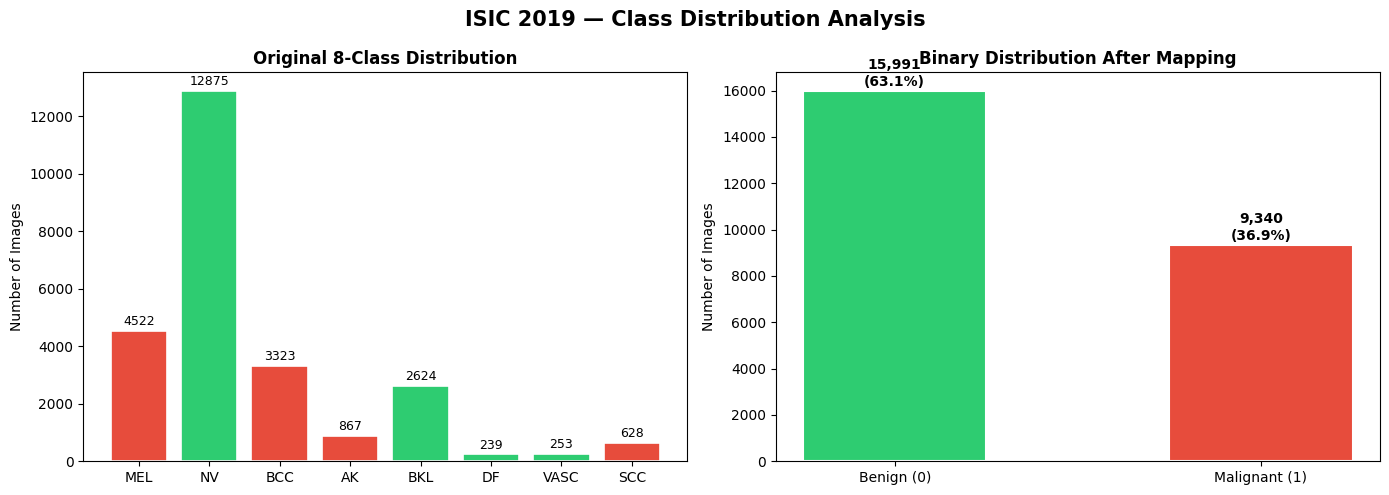

✅ Distribution plot saved.


In [4]:
# ── CODE CELL 4: Visualize Class Distribution ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ISIC 2019 — Class Distribution Analysis', fontsize=15, fontweight='bold')

# Original 8-class distribution
counts_8 = [int(df[cls].sum()) for cls in class_cols]
colors_8 = ['#e74c3c' if cls in MALIGNANT_CLASSES else '#2ecc71'
             for cls in class_cols]
axes[0].bar(class_cols, counts_8, color=colors_8, edgecolor='white', linewidth=1.2)
axes[0].set_title('Original 8-Class Distribution', fontweight='bold')
axes[0].set_ylabel('Number of Images')
for i, v in enumerate(counts_8):
    axes[0].text(i, v + 100, str(v), ha='center', va='bottom', fontsize=9)

# Binary distribution
binary_counts = [benign_count, malignant_count]
axes[1].bar(['Benign (0)', 'Malignant (1)'],
            binary_counts,
            color=['#2ecc71', '#e74c3c'],
            edgecolor='white', linewidth=1.5, width=0.5)
axes[1].set_title('Binary Distribution After Mapping', fontweight='bold')
axes[1].set_ylabel('Number of Images')
for i, v in enumerate(binary_counts):
    axes[1].text(i, v + 100, f'{v:,}\n({v/total*100:.1f}%)',
                 ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print("✅ Distribution plot saved.")


## Step 3: DullRazor — Hair Artifact Removal
Hair artifacts are one of the biggest sources of noise in dermoscopic images.
The DullRazor algorithm:
1. Converts image to grayscale
2. Applies a **morphological black-hat** filter (detects dark structures = hair)
3. Thresholds to create a binary hair mask
4. Uses **inpainting** to reconstruct the skin underneath the hair

**Published Impact: +4% to +7% improvement in classification accuracy.**

In [5]:
# ── CODE CELL 5: DullRazor Implementation ────────────────────────────
def dull_razor(image: np.ndarray,
               kernel_size: int = 17,
               threshold: int = 10) -> np.ndarray:
    """
    DullRazor Hair Removal Algorithm.
    Args:
        image      : Input BGR image (numpy array)
        kernel_size: Size of the morphological kernel (odd number)
        threshold  : Pixel intensity threshold for hair mask
    Returns:
        Inpainted image with hair removed (BGR numpy array)
    """
    # Step 1: Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Step 2: Black-hat morphological transform
    # This highlights dark structures (hair) against a lighter background
    kernel   = cv2.getStructuringElement(cv2.MORPH_CROSS,
                                          (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)

    # Step 3: Threshold to create a binary hair mask
    _, hair_mask = cv2.threshold(blackhat, threshold, 255, cv2.THRESH_BINARY)

    # Step 4: Inpaint — fill hair regions with surrounding skin texture
    cleaned = cv2.inpaint(image, hair_mask,
                           inpaintRadius=3,
                           flags=cv2.INPAINT_TELEA)
    return cleaned


In [6]:
# ── CODE CELL 6: Color Constancy — Shades of Gray ────────────────────
def shades_of_gray(image: np.ndarray, power: int = 6) -> np.ndarray:
    """
    Shades of Gray Color Constancy Algorithm.
    Normalizes lighting/color across images from different clinical devices.
    Args:
        image : Input BGR image (numpy array)
        power : Minkowski norm parameter (6 is standard for dermoscopy)
    Returns:
        Color-normalized image (BGR numpy array)
    """
    image_float = image.astype(np.float32)

    # Compute the p-norm of each channel
    norm = np.power(
        np.mean(np.power(image_float, power), axis=(0, 1)),
        1.0 / power
    )

    # Apply normalization scaling
    scale         = np.power(np.mean(norm), 1.0)
    image_scaled  = image_float * (scale / (norm + 1e-6))
    image_clipped = np.clip(image_scaled, 0, 255).astype(np.uint8)
    return image_clipped

In [7]:
# ── CODE CELL 7: Master Preprocessing Function ───────────────────────
def preprocess_image(src_path: str,
                     dst_path: str,
                     target_size: int = 224) -> bool:
    """
    Full preprocessing pipeline for one image:
    1. Load image
    2. DullRazor hair removal
    3. Shades of Gray color constancy
    4. Resize to target_size x target_size
    5. Save to destination path
    """
    img = cv2.imread(src_path)
    if img is None:
        return False

    # Apply preprocessing steps
    img = dull_razor(img)
    img = shades_of_gray(img)
    img = cv2.resize(img, (target_size, target_size),
                     interpolation=cv2.INTER_AREA)

    cv2.imwrite(dst_path, img,
                [cv2.IMWRITE_JPEG_QUALITY, 95])
    return True


## Step 4: Run Preprocessing on All Images
This loop applies DullRazor + Color Constancy to all 25,331 images.
⏱️ **Estimated Time: ~20–30 minutes on Kaggle CPU.**

Preprocessed images will be saved to `/kaggle/working/preprocessed/`
as a new "clean" image dataset that all training notebooks will use.

In [8]:
# ── CODE CELL 8: Run Preprocessing Loop ──────────────────────────────
failed_images = []

print(f"🚀 Starting preprocessing of {len(df):,} images...")
print(f"   Output directory: {PREP_DIR}")
print("-" * 55)

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Preprocessing"):
    success = preprocess_image(
        src_path    = row['image_path'],
        dst_path    = row['prep_path'],
        target_size = 224
    )
    if not success:
        failed_images.append(row['image'])

print(f"\n✅ Preprocessing complete!")
print(f"   Successfully processed : {len(df) - len(failed_images):,} images")
print(f"   Failed (missing files) : {len(failed_images)}")

# Remove failed images from dataframe
if failed_images:
    df = df[~df['image'].isin(failed_images)].reset_index(drop=True)
    print(f"   Remaining usable images: {len(df):,}")

🚀 Starting preprocessing of 25,331 images...
   Output directory: /kaggle/working/preprocessed/
-------------------------------------------------------


Preprocessing: 100%|██████████| 25331/25331 [52:18<00:00,  8.07it/s]


✅ Preprocessing complete!
   Successfully processed : 25,331 images
   Failed (missing files) : 0


📊 Generating Before/After comparison samples...


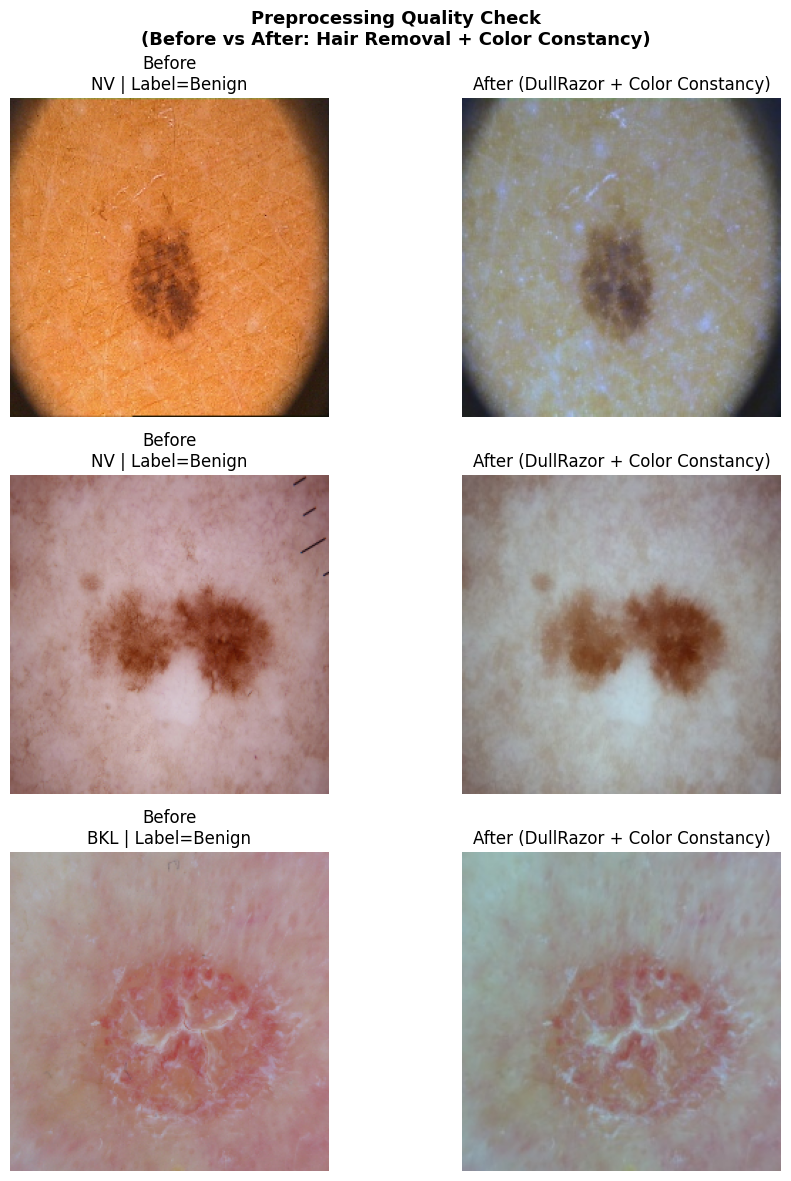

In [9]:
# ── CODE CELL 9: Visual QC — Before vs After Preprocessing ───────────
print("📊 Generating Before/After comparison samples...")

sample_indices = df.sample(3, random_state=42).index
fig, axes = plt.subplots(3, 2, figsize=(10, 12))
fig.suptitle('Preprocessing Quality Check\n(Before vs After: Hair Removal + Color Constancy)',
             fontsize=13, fontweight='bold')

for i, idx in enumerate(sample_indices):
    orig = cv2.imread(df.loc[idx, 'image_path'])
    prep = cv2.imread(df.loc[idx, 'prep_path'])

    if orig is not None:
        orig_rgb = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
        orig_rsz = cv2.resize(orig_rgb, (224, 224))
        axes[i][0].imshow(orig_rsz)
        axes[i][0].set_title(f"Before\n{df.loc[idx, 'original_class']} | "
                              f"Label={'Malignant' if df.loc[idx, 'binary_label'] else 'Benign'}")
        axes[i][0].axis('off')

    if prep is not None:
        prep_rgb = cv2.cvtColor(prep, cv2.COLOR_BGR2RGB)
        axes[i][1].imshow(prep_rgb)
        axes[i][1].set_title("After (DullRazor + Color Constancy)")
        axes[i][1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'preprocessing_qc.png'), dpi=150, bbox_inches='tight')
plt.show()

## Step 5: Stratified 80/10/10 Split

We use **Stratified** splitting to guarantee that the exact
class ratio (63% Benign / 37% Malignant) is preserved
equally in all three subsets.

- **Training Set (80%):** The model learns from this
- **Validation Set (10%):** Used after each epoch to track generalization
- **Test/Holdout Set (10%):** Locked away — only used for final evaluation

> ⚠️ **Critical:** The test set is never used during training.
> Using it during training = data leakage = inflated fake accuracy.

In [ ]:
# ── CODE CELL 10: Perform Stratified Split ────────────────────────────────
# We carry all metadata columns through the split alongside image/label.
clean_df = df[['image', 'prep_path', 'binary_label', 'original_class'] + METADATA_FEATURE_COLS].copy()
clean_df = clean_df.rename(columns={'prep_path': 'image_path'})

# Step A: Split 80% Train | 20% Temp
train_df, temp_df = train_test_split(
    clean_df,
    test_size    = 0.20,
    random_state = 42,
    stratify     = clean_df['binary_label']
)

# Step B: Split Temp into 50/50 -> 10% Val | 10% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size    = 0.50,
    random_state = 42,
    stratify     = temp_df['binary_label']
)

print("=" * 55)
print("  STRATIFIED SPLIT RESULTS")
print("=" * 55)
for name, subset in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    total  = len(subset)
    benign = (subset['binary_label'] == 0).sum()
    malig  = (subset['binary_label'] == 1).sum()
    print(f"\n  {name} Set  ({total:>6,} images)")
    print(f"    Benign    : {benign:>5,} ({benign/total*100:.1f}%)")
    print(f"    Malignant : {malig:>5,} ({malig/total*100:.1f}%)")
    print(f"    Metadata  : {len(METADATA_FEATURE_COLS)} feature columns included")

print("\n" + "=" * 55)
print("  Stratification verified -- ratios are balanced!")
print(f"  Metadata columns in CSVs: {METADATA_FEATURE_COLS}")
print("=" * 55)


In [ ]:
# ── CODE CELL 11: Export CSV Files (with Metadata) ────────────────────────
train_df.to_csv(os.path.join(OUTPUT_DIR, 'binary_train.csv'), index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR,   'binary_val.csv'),   index=False)
test_df.to_csv(os.path.join(OUTPUT_DIR,  'binary_test.csv'),  index=False)

print("CSV files exported to /kaggle/working/:")
print(f"   binary_train.csv  ->  {len(train_df):,} rows  x  {len(train_df.columns)} cols")
print(f"   binary_val.csv    ->  {len(val_df):,} rows  x  {len(val_df.columns)} cols")
print(f"   binary_test.csv   ->  {len(test_df):,} rows  x  {len(test_df.columns)} cols")
print()
print("Columns in each CSV:")
for col in train_df.columns:
    print(f"   {col}")
print()
print("Sample row from train CSV:")
print(train_df.iloc[0].to_string())


## ✅ Notebook 1 Complete

**What was produced:**
- `binary_train.csv` — Training split (80%)
- `binary_val.csv`   — Validation split (10%)
- `binary_test.csv`  — Holdout Test split (10%)
- `preprocessed/`   — All 25K images with hair removed & color normalized

**Next Steps:**
→ Run **Notebook 2** to train the **EfficientNetV2-S** model
→ Run **Notebook 3** to train the **DenseNet-121** model
→ Run **Notebook 4** to train the **Swin-Tiny** model
→ Run **Notebook 5** for Ensemble Evaluation + Final Metrics

> **Kaggle Tip:** After running this notebook, click "Save Version"
> and enable "Save & Run All". This creates a saved output dataset
> that Notebooks 2, 3, and 4 can import directly as an input.

In [12]:
print("\n🎉 Notebook 1: Data Preparation COMPLETE!")
print("   Please 'Save & Run All' and add the output as")
print("   an input dataset to Notebooks 2, 3, and 4.")


🎉 Notebook 1: Data Preparation COMPLETE!
   Please 'Save & Run All' and add the output as
   an input dataset to Notebooks 2, 3, and 4.
